# 19 - Retrieval you can count on: conformal risk control for RAG

> "Every passage we send to the model costs tokens. How few can we send without missing the
> evidence?" - Quill platform lead

Quill's third job is answering questions from a library of encyclopedia passages. For each question
it retrieves the passages that look most relevant, pastes them into the prompt and asks the model
for a short answer: **retrieval-augmented generation** (RAG). The platform lead pays for every
passage in tokens and latency; the head of learning pays for every wrong answer in student trust.
"How few can we send" is therefore a question about a promise. The sharper statistical version:
choose a **retrieval depth** (how many passages are sent to the model, either a fixed number for
every question or a similarity cut-off that lets the number vary) so that a stated promise about
future questions holds. We will meet three promises, each with its own tool. Both supporting
passages retrieved for at least 90% of questions: split conformal prediction, as in notebook 02. At
most 10% of the evidence missed on average: **conformal risk control** (CRC). And, for the answers
themselves, an error rate of at most a chosen level, certified with probability 0.9 even though more
context does not always help: **Learn then Test** (LTT).

**What you will learn**

- How to turn "retrieve the evidence" into a split conformal promise on one score per question,
  and what a similarity cut-off saves over a fixed top-k.
- Conformal risk control: the recipe, its `B/(n+1)` term, why it reproduces split conformal for
  an all-or-nothing loss, and what "at most 10% missed on average" does not promise.
- Why conformal risk control needs every question's loss to be monotone, and how Learn then Test
  certifies a depth without that assumption: one binomial test per depth, Bonferroni or
  fixed-sequence correction, and a pilot set to choose the error level before calibrating.
- Why shipping the cheapest depth whose calibration error is below epsilon is not a certificate,
  measured over thousands of redrawn calibration sets.

**Where we are in the series.** This is the last notebook of Part III. Notebook 18 kept only the
claims in an explainer that it could vouch for; this one moves the guarantee upstream, to what the
model is given to read. It leans on notebook 02 (the corrected quantile), notebook 03 (the
leaderboard argument and the coverage lottery), notebook 09 (at which level the shuffle is
plausible), notebook 16 (where the cached model outputs come from, and the procedure that must
stay fixed) and notebook 17 (ties make coverage overshoot). Field guide §24-§28 summarize Part III.

In [1]:
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)
RANDOM_SEED = 20260707
ALPHA = 0.10   # the product's 90% promise

# Series palette: blue = data, green = covered/healthy, amber = calibration/warning,
# red = missed/fault/naive, gray = reference, purple = alternative method.
BLUE, GREEN, AMBER, RED, GRAY, PURPLE = (
    "#2563EB", "#059669", "#F59E0B", "#DC2626", "#6B7280", "#7C3AED",
)

## 1. The retrieval budget

The data is the third set of real model outputs cached in `llm_data/` (notebook 16 explains how
they were generated and why a hosted model is not bit-for-bit reproducible, so the cached files
are the reference). It comes from the distractor setting of HotpotQA (Yang et al., 2018,
CC BY-SA 4.0): multi-hop questions, each delivered with ten Wikipedia passages, of which two are
**supporting passages** (the ones the annotators marked as needed for the answer) and eight are
distractors chosen to look relevant. Two question types matter here. A *bridge* question needs
one passage to find an entity and the other to look it up ("the city where the museum is
located has what population?"); a *comparison* question needs both entities' passages ("which
magazine was first published earlier?"). Three files:

- `hotpot_questions.csv`: the question, the reference answer and the type.
- `hotpot_passages.csv`: every passage with `is_supporting`, its `similarity` to the question
  (the cosine of `text-embedding-3-large` embeddings) and its `rank` (1 = most similar).
- `hotpot_answers.csv`: `gpt-4.1-mini`'s short answer when given its top-k passages, for
  k in {1, 2, 3, 5, 10}, graded by exact match and by word-overlap F1 against the reference.

One honest limitation before any number: in HotpotQA every question arrives with its own ten
candidates, so "retrieval" here means ranking ten passages, two of which are guaranteed to be the
right ones. Quill's real library holds millions of passages, and there the supporting passages may
not be among the candidates at all. The methods carry over unchanged; the numbers will not.

In [2]:
questions = pd.read_csv("llm_data/hotpot_questions.csv")
passages = pd.read_csv("llm_data/hotpot_passages.csv")
answers = pd.read_csv("llm_data/hotpot_answers.csv")

n_q = len(questions)
q_index = {qid: i for i, qid in enumerate(questions["qid"])}
qtype = questions["type"].to_numpy()

# One row per question, one column per similarity rank (column 0 = rank 1, the most similar).
# A few questions come with fewer than ten passages; their empty slots get similarity -inf,
# so no cut-off can ever "retrieve" a passage that does not exist.
row = passages["qid"].map(q_index).to_numpy()
col = passages["rank"].to_numpy() - 1
sim = np.full((n_q, 10), -np.inf)
is_sup = np.zeros((n_q, 10), dtype=bool)
tokens = np.zeros((n_q, 10))
sim[row, col] = passages["similarity"]
is_sup[row, col] = passages["is_supporting"]
# The answer prompt sends each passage as "[title] text". About four characters per token is
# the usual rule of thumb for English text and OpenAI tokenizers: an estimate, not a bill.
tokens[row, col] = (passages["title"].str.len() + passages["text"].str.len() + 5) / 4
n_passages = np.isfinite(sim).sum(axis=1)
assert (is_sup.sum(axis=1) == 2).all(), "every HotpotQA question has exactly two supporting passages"

# The two supporting passages of each question, weaker (less similar) first, and the rank of
# the deeper one: a question is fully served only once that passage is retrieved.
sup_sim = np.sort(np.where(is_sup, sim, np.inf), axis=1)[:, :2]
weak_sim = sup_sim[:, 0]
weak_rank = 10 - np.argmax(is_sup[:, ::-1], axis=1)

print(f"{n_q} questions: {(qtype == 'bridge').sum()} bridge, {(qtype == 'comparison').sum()} comparison; "
      f"{len(passages):,} passages")
print(f"questions with fewer than 10 passages: {(n_passages < 10).sum()} "
      f"(they have {sorted(n_passages[n_passages < 10].tolist())})")
real = np.isfinite(sim)
print(f"estimated tokens per passage: median {np.median(tokens[real]):.0f}, mean {tokens[real].mean():.0f}; "
      f"all passages of a question: {tokens.sum(axis=1).mean():.0f} on average")
print(f"answers: {len(answers):,} rows = {n_q} questions x depths {sorted(answers['k'].unique().tolist())}")

799 questions: 649 bridge, 150 comparison; 7,960 passages
questions with fewer than 10 passages: 5 (they have [2, 3, 4, 5, 6])
estimated tokens per passage: median 128, mean 144; all passages of a question: 1435 on average
answers: 3,995 rows = 799 questions x depths [1, 2, 3, 5, 10]


The library is 799 questions, 649 bridge and 150 comparison, with 7,960 passages: five questions
arrived from HotpotQA with fewer than ten candidates (2, 3, 4, 5 and 6), which is the dataset's
quirk, not ours, and the code above treats their empty slots as passages that can never be sent. A
passage costs about 128 tokens at the median and 144 on average, so sending all ten costs about
1,435 context tokens per question before the question itself. That is the budget the platform lead
wants to cut. The token numbers are estimates from character counts, and they run high: checked
against the prompt-token counts the API reported when the data was generated (kept in the generation
cache, not in `llm_data/`), real passages cost about 0.9 times the estimate, so all ten are closer
to 1,300 tokens. Every absolute token figure below is about 10% high; the comparisons between rules,
which are ratios, are unaffected. Do not quote them as an invoice.

rank of the weaker supporting passage: 2: 465, 3: 115, 4: 62, 5: 40, 6: 24, 7: 31, 8: 16, 9: 19, 10: 27
stronger supporting passage ranked first: 745 of 799
mean rank of the weaker one: bridge 3.58, comparison 2.18


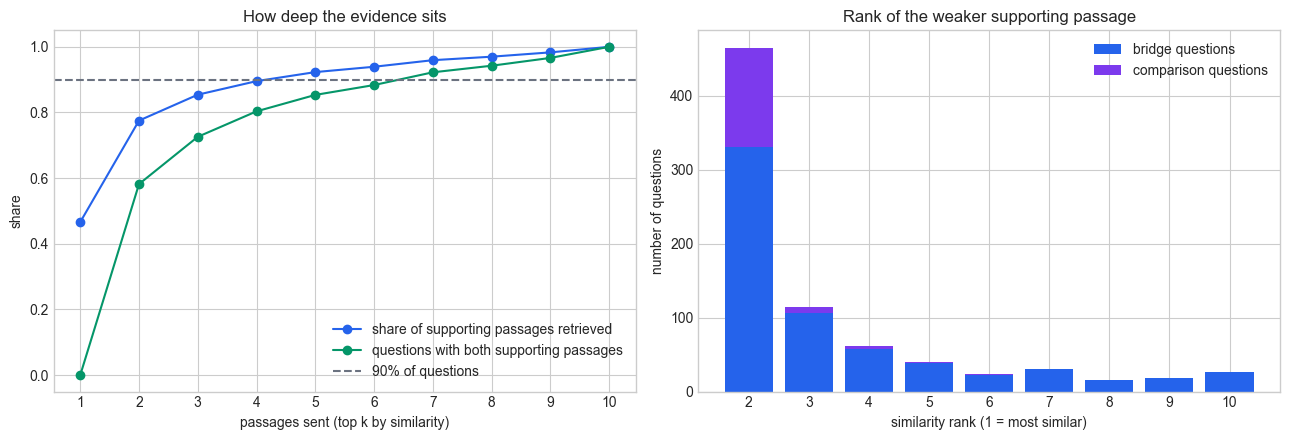

,share of supporting passages retrieved,questions with both retrieved,context tokens per question
depth k,,,
1,0.466,0.000,112.138
2,0.775,0.582,230.786
3,0.854,0.726,367.300
4,0.895,0.804,506.629
5,0.923,0.854,648.235
6,0.939,0.884,796.659
7,0.959,0.922,945.871
8,0.970,0.942,1106.529
9,0.983,0.966,1267.975


In [3]:
depths_all = np.arange(1, 11)
found = is_sup.cumsum(axis=1)              # supporting passages among the top k, k = 1..10
recall = pd.DataFrame({
    "depth k": depths_all,
    "share of supporting passages retrieved": (found / 2).mean(axis=0),
    "questions with both retrieved": (found == 2).mean(axis=0),
    "context tokens per question": tokens.cumsum(axis=1).mean(axis=0),
}).set_index("depth k")

counts = pd.Series(weak_rank).value_counts().sort_index()
print("rank of the weaker supporting passage:",
      ", ".join(f"{r}: {c}" for r, c in counts.items()))
print(f"stronger supporting passage ranked first: {(is_sup[:, 0]).sum()} of {n_q}")
print(f"mean rank of the weaker one: bridge {weak_rank[qtype == 'bridge'].mean():.2f}, "
      f"comparison {weak_rank[qtype == 'comparison'].mean():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(depths_all, recall["share of supporting passages retrieved"], color=BLUE, marker="o",
             label="share of supporting passages retrieved")
axes[0].plot(depths_all, recall["questions with both retrieved"], color=GREEN, marker="o",
             label="questions with both supporting passages")
axes[0].axhline(1 - ALPHA, color=GRAY, linestyle="--", label="90% of questions")
axes[0].set_title("How deep the evidence sits")
axes[0].set_xlabel("passages sent (top k by similarity)")
axes[0].set_ylabel("share")
axes[0].set_xticks(depths_all)
axes[0].legend(loc="lower right")

ranks = np.arange(2, 11)
bridge_counts = [(weak_rank[qtype == "bridge"] == r).sum() for r in ranks]
comp_counts = [(weak_rank[qtype == "comparison"] == r).sum() for r in ranks]
axes[1].bar(ranks, bridge_counts, color=BLUE, label="bridge questions")
axes[1].bar(ranks, comp_counts, bottom=bridge_counts, color=PURPLE, label="comparison questions")
axes[1].set_title("Rank of the weaker supporting passage")
axes[1].set_xlabel("similarity rank (1 = most similar)")
axes[1].set_ylabel("number of questions")
axes[1].set_xticks(ranks)
axes[1].legend()
plt.tight_layout()
plt.show()

recall.round(3)

The left panel is the platform lead's problem in one picture. The stronger supporting passage is
almost always the most similar one (745 of 799 questions), so a single passage already holds 46.6%
of the evidence; the weaker one is the trouble. It sits at rank 2 for 465 questions, and then the
tail is long: 115 at rank 3, 62 at rank 4, and still 27 questions where it is the least similar of
all ten. To retrieve both supporting passages for at least 90% of questions with a fixed depth you
need k = 7 (92.2% of questions; k = 6 gives 88.4%), which costs about 950 tokens per question, two
thirds of the full budget. The right panel says where the tail comes from: bridge questions, whose
second passage is about an entity the question never names (mean rank of the weaker passage 3.58,
against 2.18 for comparison questions, which name both entities). Notice what this table is not: it
describes this library, measured on every question. Nothing in it is a promise about the next
question, and it was not used to tune anything below.

Before any promise, one split, made once. Section 4 will need to choose an error level, and that
choice must be made before the calibration data is seen, so we also set aside a **pilot set**: the
questions the team may look at freely, as it would look at a pilot run before signing anything.

In [4]:
# Shuffle the questions once, then cut three non-overlapping slices. Questions are the units:
# every passage and every answer of a question travels with it (field guide §13).
rng = np.random.default_rng(RANDOM_SEED)
perm = rng.permutation(n_q)
pilot, cal, test = perm[:199], perm[199:499], perm[499:]
n_cal = len(cal)

for name, idx, role in [("pilot", pilot, "look freely; choose the error level of section 4"),
                        ("calibration", cal, "cut-offs and certificates; no choices tuned on it"),
                        ("test", test, "check each promise once, at the end")]:
    print(f"{name:<12}{len(idx):>4} questions ({(qtype[idx] == 'comparison').mean():.0%} comparison) -> {role}")

pilot        199 questions (20% comparison) -> look freely; choose the error level of section 4
calibration  300 questions (19% comparison) -> cut-offs and certificates; no choices tuned on it
test         300 questions (17% comparison) -> check each promise once, at the end


| Slice | Questions | What it is for | What must not happen |
|---|---|---|---|
| pilot | 199 | answer-quality curves and the choice of the error level in section 4 | nothing is certified on it |
| calibration | 300 | every cut-off, every risk-control choice and every certificate | choosing the error level, the candidates or the test order after looking at it |
| test | 300 | checking each promise once | tuning anything to make it look good |

The comparison shares (20%, 19% and 17%) are close to the library's 19%, as a random split should
make them. Sections 2 and 3 never touch the pilot: their budget, alpha = 0.10, was fixed before
the split. The pilot plays the role notebook 02 gave the validation set: it is where you are allowed
to look and to choose, while the calibration set only measures.

## 2. A coverage promise: retrieve all the evidence

The first promise is the one the platform lead asked for, read literally: send few passages, but
send both supporting passages for at least 90% of questions. In words, the recipe is notebook 02's
with a new score:

1. For each calibration question, find the similarity of its *weaker* supporting passage. Both
   supporting passages are retrieved by a cut-off exactly when that similarity is at or above it.
2. Score each calibration question by *minus* that similarity, so that, as in notebook 02, a
   larger score is a harder question (its evidence hides deeper).
3. Take the corrected quantile of the scores. Minus that quantile is the similarity cut-off.
4. For a new question, send every passage whose similarity is at or above the cut-off.

The leaderboard argument of notebook 03 then applies verbatim: the new question's score is one of
n + 1 exchangeable scores, so it falls at or below the corrected quantile, and its weaker supporting
passage clears the cut-off, with probability at least 0.90. The units are questions, not passages
(field guide §13): one score per question, and the promise is about a new question drawn like the
calibration ones. The same recipe with the *rank* of the weaker passage as the score gives the
best fixed top-k, which is our baseline. The cut-off is still a retrieval depth: it decides how many
passages each question receives, but the number now varies from question to question.

In [5]:
def corrected_quantile(scores, alpha):
    """The corrected quantile from notebook 02 (finite-sample, slightly conservative)."""
    n = len(scores)
    q_level = math.ceil((n + 1) * (1 - alpha)) / n
    assert q_level <= 1.0, "calibration window too short for this alpha (field guide S1)"
    return float(np.quantile(scores, q_level, method="higher"))


# A similarity cut-off: score = minus the similarity of the weaker supporting passage.
cutoff_sc = -corrected_quantile(-weak_sim[cal], ALPHA)
send_sc = sim[test] >= cutoff_sc                    # which passages each test question receives
# The fixed top-k baseline: score = rank of the weaker supporting passage.
k_sc = int(corrected_quantile(weak_rank[cal], ALPHA))

print(f"similarity cut-off: {cutoff_sc:.3f}  |  fixed depth: top {k_sc}")
print(f"test questions with both supporting passages: cut-off {(weak_sim[test] >= cutoff_sc).mean():.3f}, "
      f"top-{k_sc} {(weak_rank[test] <= k_sc).mean():.3f}")
print(f"passages sent per question: cut-off {send_sc.sum(axis=1).mean():.2f}, "
      f"top-{k_sc} {np.minimum(k_sc, n_passages[test]).mean():.2f}")
print(f"context tokens per question: cut-off {(tokens[test] * send_sc).sum(axis=1).mean():.0f}, "
      f"top-{k_sc} {tokens[test, :k_sc].sum(axis=1).mean():.0f}, all ten {tokens[test].sum(axis=1).mean():.0f}")

similarity cut-off: 0.332  |  fixed depth: top 7
test questions with both supporting passages: cut-off 0.923, top-7 0.910
passages sent per question: cut-off 6.19, top-7 7.00
context tokens per question: cut-off 796, top-7 934, all ten 1400


On the 300 test questions both rules keep the promise: the similarity cut-off of 0.332 retrieves
both supporting passages for 92.3% of questions, the top-7 rule for 91.0%. The cut-off does it with
6.19 passages per question against 7.00, about 800 context tokens against 930, and the full ten
would have cost about 1,400. One test set is one draw, though, and a single calibration set is a
lottery ticket (notebook 03 §5, field guide §4). The next cell redraws the calibration and test
halves a thousand times from the same 600 questions. It also runs the cut-off at alpha = 0.08, for a
reason the output will make plain: top-k cannot hit 90% exactly.

In [6]:
rng_splits = np.random.default_rng(RANDOM_SEED + 1)
pool = np.concatenate([cal, test])
records = []
for rep in range(1000):
    shuffled = rng_splits.permutation(pool)
    c, t = shuffled[:n_cal], shuffled[n_cal:]
    for alpha in (0.10, 0.08):
        cut = -corrected_quantile(-weak_sim[c], alpha)
        send = sim[t] >= cut
        records.append({"rule": f"similarity cut-off, alpha = {alpha:.2f}",
                        "coverage": (weak_sim[t] >= cut).mean(),
                        "passages": send.sum(axis=1).mean(),
                        "tokens": (tokens[t] * send).sum(axis=1).mean()})
    k = int(corrected_quantile(weak_rank[c], 0.10))
    records.append({"rule": "fixed top-k, alpha = 0.10", "k": k,
                    "coverage": (weak_rank[t] <= k).mean(),
                    "passages": np.minimum(k, n_passages[t]).mean(),
                    "tokens": tokens[t, :k].sum(axis=1).mean()})

reps = pd.DataFrame(records)
print("top-k depth chosen across redraws:", reps["k"].dropna().astype(int).value_counts().sort_index().to_dict())
summary = reps.groupby("rule", sort=False).agg(
    mean_coverage=("coverage", "mean"),
    coverage_5th_pct=("coverage", lambda s: s.quantile(0.05)),
    coverage_95th_pct=("coverage", lambda s: s.quantile(0.95)),
    passages_per_question=("passages", "mean"),
    tokens_per_question=("tokens", "mean"),
)
summary.round(3)

top-k depth chosen across redraws: {6: 15, 7: 877, 8: 108}


,mean_coverage,coverage_5th_pct,coverage_95th_pct,passages_per_question,tokens_per_question
rule,,,,,
"similarity cut-off, alpha = 0.10",0.903,0.860,0.940,6.038,781.603
"similarity cut-off, alpha = 0.08",0.922,0.883,0.957,6.334,827.164
"fixed top-k, alpha = 0.10",0.919,0.900,0.953,7.073,959.092


Averaged over a thousand redraws the similarity cut-off covers 0.903, the promise and a whisker,
with the usual lottery around it: the middle 90% of redraws run from about 0.86 to 0.94, so a single
deployment can land a few points either side (field guide §4). The fixed top-k rule covers 0.919 on
average, and the reason is not that it is safer. The rank of the weaker passage takes only nine
values, so the corrected quantile lands on k = 7 in 877 redraws of 1,000, and a depth of 7 covers
about 92% of questions whatever the budget asks for: the same overshoot that ties caused in notebook
17. A fair price comparison therefore needs equal coverage. At alpha = 0.08 the cut-off matches
top-k's coverage (0.922 against 0.919) with 6.33 passages instead of 7.07, and about 830 tokens
instead of 960. At the promised 90% it sends 6.04 passages. The saving is real but modest, about 0.7
of a passage per question, or 14% of the tokens, at equal coverage, and it comes from letting the
number of passages vary: a question whose distractors look unlike the question receives few
passages, one where everything looks relevant receives many.

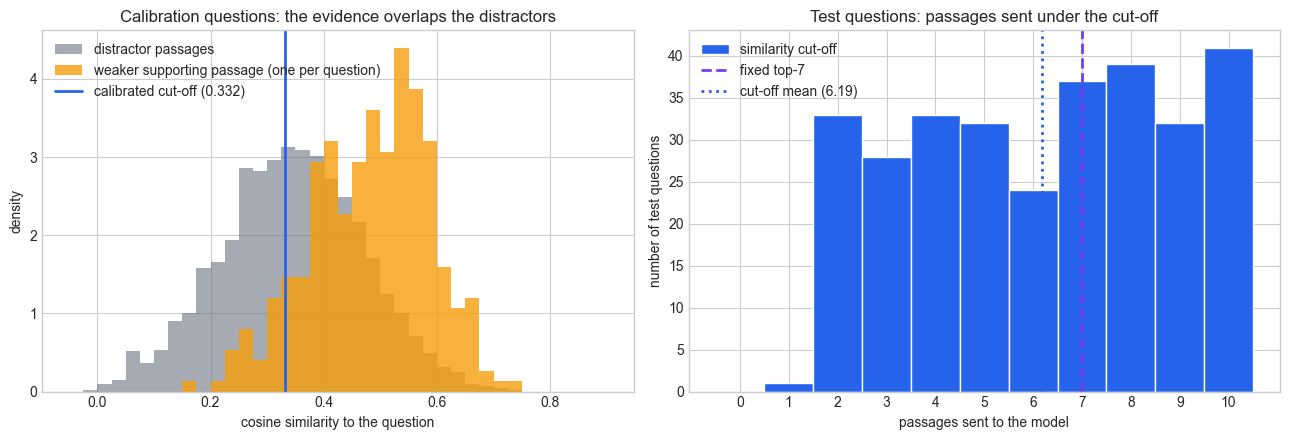

test questions sent a single passage: 1, all ten: 41
bridge      (248 test questions): both retrieved 0.907, passages sent 6.185
comparison  ( 52 test questions): both retrieved 1.000, passages sent 6.192


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
distractor_sim = sim[cal][~is_sup[cal] & np.isfinite(sim[cal])]
bins = np.linspace(-0.05, 0.9, 39)
axes[0].hist(distractor_sim, bins=bins, density=True, color=GRAY, alpha=0.6, label="distractor passages")
axes[0].hist(weak_sim[cal], bins=bins, density=True, color=AMBER, alpha=0.8,
             label="weaker supporting passage (one per question)")
axes[0].axvline(cutoff_sc, color=BLUE, linewidth=2, label=f"calibrated cut-off ({cutoff_sc:.3f})")
axes[0].set_title("Calibration questions: the evidence overlaps the distractors")
axes[0].set_xlabel("cosine similarity to the question")
axes[0].set_ylabel("density")
axes[0].legend()

sent = send_sc.sum(axis=1)
axes[1].hist(sent, bins=np.arange(-0.5, 11.5, 1), color=BLUE, edgecolor="white",
             label="similarity cut-off")
axes[1].axvline(k_sc, color=PURPLE, linewidth=2, linestyle="--", label=f"fixed top-{k_sc}")
axes[1].axvline(sent.mean(), color=BLUE, linewidth=2, linestyle=":", label=f"cut-off mean ({sent.mean():.2f})")
axes[1].set_title("Test questions: passages sent under the cut-off")
axes[1].set_xlabel("passages sent to the model")
axes[1].set_ylabel("number of test questions")
axes[1].set_xticks(range(0, 11))
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"test questions sent a single passage: {(sent == 1).sum()}, all ten: {(sent == 10).sum()}")
for t in ("bridge", "comparison"):
    m = qtype[test] == t
    print(f"{t:<11} ({m.sum():>3} test questions): both retrieved {(weak_sim[test][m] >= cutoff_sc).mean():.3f}, "
          f"passages sent {sent[m].mean():.3f}")

The left panel shows why the evidence cannot be had cheaply: the weaker supporting passages
(amber) overlap the distractors (gray) heavily, so any cut-off low enough to catch nine in ten of
them also lets many distractors through. The right panel shows what a per-question cut-off does
with that: one test question received a single passage, 41 received all ten, and the rest spread
in between, with a mean of 6.19. The printout below the plot is notebook 03's lesson in a new
costume (field guide §3). The promise is marginal: bridge questions get both supporting passages
90.7% of the time and comparison questions 100%, while both types receive almost the same number of
passages (6.185 and 6.192). The cut-off cannot see question types; it spends the same on the easy
type as on the hard one. If the comparison questions matter on their own, calibrate per type, as
notebook 04 did per class.

## 3. Conformal risk control: miss little on average

Section 2's promise is all-or-nothing: a question counts as a miss whether it lost one supporting
passage or both. The platform lead may reasonably prefer a softer promise that is cheaper to keep:
"on average, we miss at most 10% of the evidence". That is a promise about an expected *loss*, and
conformal risk control (Angelopoulos, Bates, Fisch, Lei and Schuster, "Conformal risk control",
ICLR 2024) is the tool for it. The loss of a question is the share of its two supporting passages
that the depth rule fails to send: 0, 0.5 or 1. The recipe in words:

1. Line up the candidate settings from the strictest (fewest passages) to the loosest (send
   everything). For each, compute every calibration question's loss.
2. For each setting, average the losses over the n calibration questions, then inflate the average
   slightly, as if one more question (tomorrow's) had arrived with the worst possible loss B.
3. Choose the strictest setting whose inflated average is at most alpha.

In symbols, after the words: let $\lambda$ be the setting, growing as more passages are sent (the
depth k for top-k, or minus the similarity cut-off), let $L_i(\lambda)$ be calibration question
$i$'s loss at that setting, $\hat R_n(\lambda) = \frac{1}{n}\sum_{i=1}^n L_i(\lambda)$ their
average, and $B$ an upper bound on any loss (here $B = 1$). Then

$$\hat\lambda = \inf\Big\{\lambda : \frac{n}{n+1}\,\hat R_n(\lambda) + \frac{B}{n+1} \le \alpha\Big\},$$

and the theorem says $\mathbb{E}\big[L_{n+1}(\hat\lambda)\big] \le \alpha$: the expected loss of a
new question is at most alpha, the expectation taken over the calibration draw and the new
question together. It needs exchangeable questions, a bounded loss, a loss that never increases as
$\lambda$ loosens, *for every question*, and a loosest setting whose loss is at most alpha (sending
all ten passages misses nothing).

Why it works, in one paragraph. Imagine we could see tomorrow's question too, and chose the
setting from all n + 1 loss curves: the strictest one whose (n + 1)-average is at most alpha. That
choice treats the n + 1 questions symmetrically, so tomorrow's question is one exchangeable peer
among n + 1, and its expected loss equals the expected average, at most alpha: notebook 03's
leaderboard argument, applied to losses instead of ranks. We cannot see tomorrow's loss, so we
replace it by the worst case B; that can only raise the inflated average, so our setting is at
least as loose as the clairvoyant one. Because every question's loss can only fall as the setting
loosens, tomorrow's loss at our setting is no larger than at the clairvoyant one. Monotonicity is
used exactly once, in that last step, and it is a property of each question's loss curve, not of
the average. Hold on to that for section 4.

In [8]:
def crc_choose(losses, alpha, B=1.0):
    """Conformal risk control (Angelopoulos, Bates, Fisch, Lei and Schuster, 2024).

    losses[i, j] is calibration question i's loss under candidate setting j, the candidates
    ordered from the strictest (fewest passages) to the loosest. Every row must be
    non-increasing: the theorem needs this for EVERY question, not only on average.
    B bounds the loss. Returns the index of the strictest candidate whose inflated risk
    n/(n+1) * mean loss + B/(n+1) is at most alpha; then E[loss of a new question] <= alpha.
    """
    n = losses.shape[0]
    assert np.all(np.diff(losses, axis=1) <= 0), "a question's loss rose as the setting loosened"
    inflated = n / (n + 1) * losses.mean(axis=0) + B / (n + 1)
    assert inflated[-1] <= alpha, "even the loosest setting fails: alpha is below B/(n+1)"
    return int(np.argmax(inflated <= alpha))


def miss_share(cutoffs, sup):
    """Share of each question's two supporting passages below each cut-off: (questions x cut-offs)."""
    return (sup[:, :, None] < cutoffs[None, None, :]).mean(axis=1)


# Candidate cut-offs: the calibration losses only change at the supporting similarities, so
# those are the only cut-offs worth trying; strictest (highest) first, -inf = send everything.
candidates = np.append(np.sort(sup_sim[cal].ravel())[::-1], -np.inf)
loss_cal = miss_share(candidates, sup_sim[cal])
cutoff_crc = candidates[crc_choose(loss_cal, ALPHA)]
send_crc = sim[test] >= cutoff_crc
print(f"CRC similarity cut-off: {cutoff_crc:.3f} "
      f"({(sup_sim[cal] < cutoff_crc).sum()} of {2 * n_cal} calibration supporting passages fall below it)")

# The same machine with an all-or-nothing loss (1 if either passage is missed) is split conformal.
loss01_cal = (weak_sim[cal][:, None] < candidates[None, :]).astype(float)
cutoff_01 = candidates[crc_choose(loss01_cal, ALPHA)]
rank_exact = math.ceil((n_cal + 1) * (1 - ALPHA))
exact = np.sort(weak_sim[cal])[n_cal - rank_exact]          # the exact order statistic of notebook 03
assert cutoff_01 == exact, "CRC with a 0/1 loss is split conformal at the exact rank"
print(f"CRC with the all-or-nothing loss: {cutoff_01:.4f} = the exact rank-{rank_exact} score "
      f"(the series idiom of section 2 gave {cutoff_sc:.4f}, one score lower)")

# Fixed top-k with the share-missed loss: candidates k = 1..10.
loss_topk_cal = 1 - is_sup[cal].cumsum(axis=1) / 2
k_crc = crc_choose(loss_topk_cal, ALPHA) + 1
print(f"CRC fixed depth: top {k_crc} (calibration share missed at k = 4: "
      f"{loss_topk_cal[:, 3].mean():.3f}, at k = 5: {loss_topk_cal[:, 4].mean():.3f})")

CRC similarity cut-off: 0.388 (58 of 600 calibration supporting passages fall below it)
CRC with the all-or-nothing loss: 0.3328 = the exact rank-271 score (the series idiom of section 2 gave 0.3324, one score lower)
CRC fixed depth: top 5 (calibration share missed at k = 4: 0.110, at k = 5: 0.073)


Conformal risk control picks a cut-off of 0.388, noticeably stricter than section 2's 0.332: 58 of
the 600 calibration supporting passages fall below it, the most the inflated average allows
(n/(n+1) times 58/600 plus 1/301 is 0.0997). The second printout is a check worth running on any
implementation. With the all-or-nothing loss the same function returns the exact rank-271 score of
the calibration questions, which is split conformal at the exact rank of notebook 03; the series'
`np.quantile(..., method="higher")` idiom of section 2 landed one score lower, the one seat of
harmless conservatism notebook 02 §3 warned about. So conformal risk control does not replace split
conformal, it contains it: change the loss and the same three lines give either promise. For a
fixed depth, the share missed at k = 4 is 0.110 on the calibration set, too much once inflated, so
CRC picks top 5.

In [9]:
def outcomes(send, sup_mask, tok):
    """Passages sent, tokens, share of evidence missed and questions missing evidence."""
    missed = (sup_mask & ~send).sum(axis=1)
    return {"passages sent": send.sum(axis=1).mean(), "context tokens": (tok * send).sum(axis=1).mean(),
            "share of evidence missed": (missed / 2).mean(), "questions missing one": (missed == 1).mean(),
            "questions missing both": (missed == 2).mean()}


depth_mask = lambda k: np.arange(10)[None, :] < k          # top-k as a mask over ranks
rules = {
    ("all ten passages", "none needed"): np.isfinite(sim[test]),
    (f"split conformal, top {k_sc}", "both retrieved for 90% of questions"): depth_mask(k_sc) & np.isfinite(sim[test]),
    ("split conformal, cut-off", "both retrieved for 90% of questions"): send_sc,
    (f"CRC, top {k_crc}", "at most 10% of evidence missed on average"): depth_mask(k_crc) & np.isfinite(sim[test]),
    ("CRC, cut-off", "at most 10% of evidence missed on average"): send_crc,
}
table = pd.DataFrame({key: outcomes(send, is_sup[test], tokens[test]) for key, send in rules.items()}).T
table.index.names = ["rule", "promise"]
table.round(3)

,,passages sent,context tokens,share of evidence missed,questions missing one,questions missing both
rule,promise,,,,,
all ten passages,none needed,9.987,1400.032,0.000,0.000,0.000
"split conformal, top 7",both retrieved for 90% of questions,6.997,933.878,0.048,0.083,0.007
"split conformal, cut-off",both retrieved for 90% of questions,6.187,795.650,0.040,0.073,0.003
"CRC, top 5",at most 10% of evidence missed on average,5.000,647.579,0.088,0.157,0.010
"CRC, cut-off",at most 10% of evidence missed on average,4.660,586.471,0.092,0.177,0.003


Read the table from top to bottom as a price list on the 300 test questions. Sending everything
costs about 1,400 tokens and misses nothing. The split conformal cut-off cuts that to about 800
tokens; 7.3% of questions lose one supporting passage and one question loses both. Conformal risk
control with a cut-off sends 4.66 passages, about 590 tokens, and misses 9.2% of the evidence on
average, inside its 10% promise, with about a quarter fewer tokens than the all-or-nothing promise.
Now the line the platform lead must read twice, because it is the whole of field guide §28: "9.2% of
the evidence missed on average" is made of 17.7% of questions losing one supporting passage, plus
one question losing both. An expected loss of 10% does not say that each question misses at most
10%, and it cannot: a question misses nothing, half or all of its evidence. With this loss, a 10%
average budget permits roughly one question in five to lose its weaker passage. If what Quill needs
is "rarely lose any evidence", that is section 2's promise, and it costs about 210 tokens more per
question.

CRC over 1,000 redraws: share of evidence missed 0.0977 on average (5th-95th percentile 0.072 to 0.127); questions missing any 0.192; passages 4.67


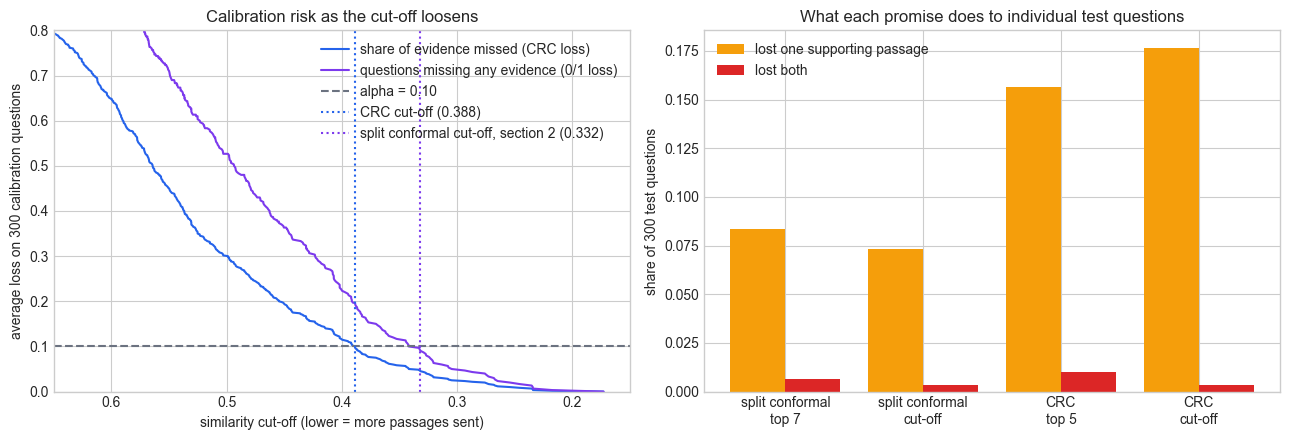

In [10]:
rng_crc = np.random.default_rng(RANDOM_SEED + 2)
crc_reps = []
for rep in range(1000):
    shuffled = rng_crc.permutation(pool)
    c, t = shuffled[:n_cal], shuffled[n_cal:]
    cands = np.append(np.sort(sup_sim[c].ravel())[::-1], -np.inf)
    cut = cands[crc_choose(miss_share(cands, sup_sim[c]), ALPHA)]
    missed = (sup_sim[t] < cut).sum(axis=1)
    crc_reps.append({"share missed": (missed / 2).mean(), "missing any": (missed > 0).mean(),
                     "passages": (sim[t] >= cut).sum(axis=1).mean()})
crc_reps = pd.DataFrame(crc_reps)
print(f"CRC over 1,000 redraws: share of evidence missed {crc_reps['share missed'].mean():.4f} on average "
      f"(5th-95th percentile {crc_reps['share missed'].quantile(0.05):.3f} to {crc_reps['share missed'].quantile(0.95):.3f}); "
      f"questions missing any {crc_reps['missing any'].mean():.3f}; passages {crc_reps['passages'].mean():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(candidates[:-1], loss_cal.mean(axis=0)[:-1], color=BLUE,
             label="share of evidence missed (CRC loss)")
axes[0].plot(candidates[:-1], loss01_cal.mean(axis=0)[:-1], color=PURPLE,
             label="questions missing any evidence (0/1 loss)")
axes[0].axhline(ALPHA, color=GRAY, linestyle="--", label="alpha = 0.10")
axes[0].axvline(cutoff_crc, color=BLUE, linestyle=":", label=f"CRC cut-off ({cutoff_crc:.3f})")
axes[0].axvline(cutoff_sc, color=PURPLE, linestyle=":", label=f"split conformal cut-off, section 2 ({cutoff_sc:.3f})")
axes[0].invert_xaxis()   # moving right = lower cut-off = more passages sent
axes[0].set_xlim(0.65, 0.15)
axes[0].set_ylim(0, 0.8)
axes[0].set_title("Calibration risk as the cut-off loosens")
axes[0].set_xlabel("similarity cut-off (lower = more passages sent)")
axes[0].set_ylabel("average loss on 300 calibration questions")
axes[0].legend(loc="upper right")

shown = [(f"split conformal, top {k_sc}", f"split conformal\ntop {k_sc}"), ("split conformal, cut-off", "split conformal\ncut-off"),
         (f"CRC, top {k_crc}", f"CRC\ntop {k_crc}"), ("CRC, cut-off", "CRC\ncut-off")]
by_rule = table.reset_index(level="promise", drop=True)
pos = np.arange(len(shown))
axes[1].bar(pos - 0.2, [by_rule.loc[r, "questions missing one"] for r, _ in shown], width=0.4, color=AMBER,
            label="lost one supporting passage")
axes[1].bar(pos + 0.2, [by_rule.loc[r, "questions missing both"] for r, _ in shown], width=0.4, color=RED,
            label="lost both")
axes[1].set_xticks(pos)
axes[1].set_xticklabels([lab for _, lab in shown])
axes[1].set_title("What each promise does to individual test questions")
axes[1].set_ylabel("share of 300 test questions")
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

Across a thousand redraws of the 600 calibration-and-test questions, the share of evidence missed
averages 0.0977, the theorem's at most 0.10 kept with almost nothing to spare, which is what the
inflation term is designed to do: under mild extra conditions the paper also shows the expected loss
is at least alpha - 2B/(n+1), so CRC wastes little. The spread is the lottery again: from 0.072 to
0.127 in the middle 90% of redraws. That is the second thing "expected" hides. The theorem averages
over calibration draws too, so a single deployment, which rides one calibration set, can sit at 12
or 13% (notebook 03 §5); section 4's tool is the one that controls that. The left panel shows the
two losses side by side: the share missed (blue) always sits below the all-or-nothing loss (purple),
because missing one passage of two counts half, so it reaches alpha at a stricter cut-off. The right
panel is the price in individual questions: under CRC, 17% to 18% of test questions lose at least
one supporting passage, against 8% to 9% under split conformal.

## 4. When more context is not better: Learn then Test

Evidence is a means; the head of learning cares about answers. `hotpot_answers.csv` holds the
model's answer at five depths, and the natural loss is now "the answer is wrong". Two things change.
The loss is no longer guaranteed to fall as depth grows: an extra passage can distract the model,
and long contexts are known to hurt some models (Liu and colleagues, "Lost in the middle", 2024).
And the promise the head of learning wants is not an expectation but a certificate for the depth
we ship: "with probability at least 0.9, answers at this depth are wrong at most a fraction
epsilon of the time". Both changes point to Learn then Test (Angelopoulos, Bates, Candes,
Jordan and Lei, 2021, published 2025). We use it, like conformal risk control, only to choose the
depth.

First the grader, because the guarantee will be about it (the point field guide §27 made for
factuality). Exact match is too harsh for a model told to reply in a few words: it rejects
"Ashanti Region" for "Ashanti Region of Ghana". We count an answer as right when its word-overlap
F1 with the reference (the harmonic mean of the shared-word precision and recall, after removing
case, punctuation and articles) is at least 0.5. That forgives a missing qualifier and still
rejects most wrong entities. It is not perfect, and the cell below shows exactly where it errs.

In [11]:
DEPTHS = np.array([1, 2, 3, 5, 10])
f1 = answers.pivot(index="qid", columns="k", values="f1").reindex(questions["qid"])[DEPTHS].to_numpy()
em = answers.pivot(index="qid", columns="k", values="exact_match").reindex(questions["qid"])[DEPTHS].to_numpy()
wrong = f1 < 0.5            # the correctness rule: F1 >= 0.5 counts as right

print(f"pilot error rate at depths {DEPTHS.tolist()}:")
print(f"  exact match : {np.round(1 - em[pilot].astype(float).mean(axis=0), 3)}")
print(f"  F1 >= 0.5   : {np.round(wrong[pilot].mean(axis=0), 3)}")
on_boundary = (f1 == 0.5)
print(f"pilot answers with F1 exactly 0.5: {on_boundary[pilot].sum()} of {on_boundary[pilot].size}")

pilot_answers = answers.merge(questions[["qid", "answer"]], on="qid")
pilot_answers = pilot_answers[pilot_answers["qid"].isin(questions["qid"].iloc[pilot])]
borderline = (pilot_answers[pilot_answers["f1"] == 0.5]
              .drop_duplicates(["qid", "model_answer"])
              [["qid", "k", "answer", "model_answer"]]
              .rename(columns={"answer": "reference answer", "model_answer": "model answer"}))
borderline.set_index("qid")

pilot error rate at depths [1, 2, 3, 5, 10]:
  exact match : [0.678 0.513 0.482 0.457 0.402]
  F1 >= 0.5   : [0.528 0.332 0.266 0.221 0.156]
pilot answers with F1 exactly 0.5: 36 of 995


,k,reference answer,model answer
qid,,,
hotpot_0132,1,Tamworth,Tamworth and Walcha
hotpot_0182,1,300,Around 300 houses
hotpot_0208,1,DS Virgin Racing Formula E Team,Formula E
hotpot_0226,1,Louisville RiverBats,Louisville Bats
hotpot_0318,5,French and English,"Shoshone, French, English, German, Spanish"
hotpot_0352,2,restaurant chain,Restaurant chains
hotpot_0447,1,Preston County,Monongalia County
hotpot_0557,2,Kansas,"Overland Park, Kansas"
hotpot_0578,1,life insurance,Insurance business


The first printout says how much the grader matters: on the pilot, exact match calls 40.2% of the
depth-10 answers wrong, the F1 rule 15.6%, and every number below inherits that choice. The table
shows the 13 distinct pilot answers sitting exactly on the boundary (36 of the pilot's 995 answers
score exactly 0.5), and they cut both ways. Several are fine answers the rule rightly accepts:
"Around 300 houses" for "300", "Restaurant chains" for "restaurant chain". Some are wrong answers it
wrongly accepts, because a shared word is half of a two-word answer: "Monongalia County" for
"Preston County", "Greek alphabet" for "Phoenician alphabet", and "Louisville Bats" for "Louisville
RiverBats", which is the team's current name given to a question that asks for its former one. A
stricter rule (F1 above 0.5) would reject those and also the good ones. No rule is right everywhere;
we chose this one before looking at the calibration data, and the certificate below is a certificate
about this grader, which the product review must say.

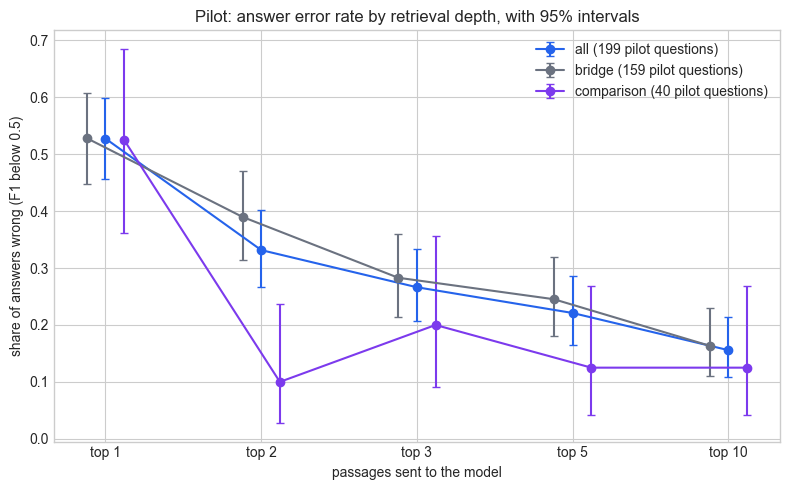

pilot questions right at some depth and wrong at a deeper one: 13 of 199
largest dip: comparison questions, depth 2 -> 3: 4 answers lost, 0 gained; one-sided sign test p = 0.062; chance that at least one of 8 such steps looks this bad by luck, roughly 0.40
hotpot_0226 (pilot): What is the former name of the team that Tom Shearn was supposed to start for? reference: Louisville RiverBats
  top 1: Louisville Bats (F1 0.5, supporting passages sent 1); top 2: Louisville RiverBats (F1 1.0, supporting passages sent 2); top 3: Louisville RiverBats (F1 1.0, supporting passages sent 2); top 5: Louisville Bats (F1 0.5, supporting passages sent 2); top 10: Louisville Bats (F1 0.5, supporting passages sent 2)


In [12]:
def clopper_pearson(x, n, level=0.95):
    """Exact two-sided confidence interval for a binomial proportion x / n."""
    lo = stats.beta.ppf((1 - level) / 2, x, n - x + 1) if x > 0 else 0.0
    hi = stats.beta.ppf(1 - (1 - level) / 2, x + 1, n - x) if x < n else 1.0
    return lo, hi


fig, ax = plt.subplots(figsize=(8, 5))
offsets = {"all": 0.0, "bridge": -0.12, "comparison": 0.12}
colors = {"all": BLUE, "bridge": GRAY, "comparison": PURPLE}
for group, offset in offsets.items():
    idx = pilot if group == "all" else pilot[qtype[pilot] == group]
    x = wrong[idx].sum(axis=0)
    ci = np.array([clopper_pearson(xi, len(idx)) for xi in x])
    rate = x / len(idx)
    pos = np.arange(len(DEPTHS)) + offset
    ax.errorbar(pos, rate, yerr=[rate - ci[:, 0], ci[:, 1] - rate], color=colors[group], marker="o",
                capsize=3, label=f"{group} ({len(idx)} pilot questions)")
ax.set_xticks(np.arange(len(DEPTHS)))
ax.set_xticklabels([f"top {k}" for k in DEPTHS])
ax.set_title("Pilot: answer error rate by retrieval depth, with 95% intervals")
ax.set_xlabel("passages sent to the model")
ax.set_ylabel("share of answers wrong (F1 below 0.5)")
ax.legend()
plt.tight_layout()
plt.show()

# Per question: does a deeper depth ever turn a right answer wrong?
flipped = np.zeros(n_q, dtype=bool)
for j in range(len(DEPTHS)):
    for jj in range(j + 1, len(DEPTHS)):
        flipped |= ~wrong[:, j] & wrong[:, jj]
print(f"pilot questions right at some depth and wrong at a deeper one: {flipped[pilot].sum()} of {len(pilot)}")
rows = []
for group in ("bridge", "comparison"):
    idx = pilot[qtype[pilot] == group]
    for j in range(len(DEPTHS) - 1):
        hurt = int((~wrong[idx, j] & wrong[idx, j + 1]).sum())
        helped = int((wrong[idx, j] & ~wrong[idx, j + 1]).sum())
        p = stats.binomtest(hurt, hurt + helped, 0.5, alternative="greater").pvalue if hurt + helped else 1.0
        rows.append({"type": group, "step": f"{DEPTHS[j]} -> {DEPTHS[j + 1]}",
                     "right became wrong": hurt, "wrong became right": helped, "sign-test p": p})
steps = pd.DataFrame(rows)
worst = steps.loc[steps["sign-test p"].idxmin()]
print(f"largest dip: {worst['type']} questions, depth {worst['step']}: {worst['right became wrong']} answers lost, "
      f"{worst['wrong became right']} gained; one-sided sign test p = {worst['sign-test p']:.3f}; "
      f"chance that at least one of {len(steps)} such steps looks this bad by luck, roughly "
      f"{1 - (1 - worst['sign-test p']) ** len(steps):.2f}")
case = answers[answers["qid"] == "hotpot_0226"].set_index("k")
print(f"hotpot_0226 ({'pilot' if q_index['hotpot_0226'] in set(pilot) else 'not pilot'}): "
      f"{questions.loc[q_index['hotpot_0226'], 'question']} "
      f"reference: {questions.loc[q_index['hotpot_0226'], 'answer']}")
print("  " + "; ".join(f"top {k}: {case.loc[k, 'model_answer']} (F1 {case.loc[k, 'f1']:.1f}, "
                       f"supporting passages sent {int(found[q_index['hotpot_0226'], min(k, 10) - 1])})"
                       for k in DEPTHS))

Say it plainly: on average, error here falls with depth, and close to monotonically. On the 199
pilot questions it drops from 52.8% with one passage to 15.6% with ten, and every step is downhill
for the pilot as a whole. Comparison questions show no clear trend after two passages, and the one
visible bump, from 10.0% at depth 2 to 20.0% at depth 3, is four answers among 40 questions: four
answers went from right to wrong and none the other way, a one-sided sign test gives p = 0.062, and
with eight such steps on the table, one this extreme turns up by luck about two times in five. The
95% intervals overlap heavily. This is not evidence of a real dip, and we will not call it one.

The per-question picture is different, and it is the one that matters for the theory. 13 of the 199
pilot questions were answered right at some depth and wrong at a deeper one. Their loss curve goes
up as the setting loosens, which breaks the one assumption conformal risk control used in its last
step (section 3: "for every question"), even though the average curve looks well behaved. The
authors give examples in which, without monotonicity, the expected loss of CRC's choice ends up far
above alpha. The grader can also hide a flip, and the last printout shows one: `hotpot_0226` asks
for the *former* name of a baseball team. The model answers "Louisville RiverBats", right, at depths
2 and 3, where both supporting passages are present, and "Louisville Bats", the current name, at
depth 1 (one supporting passage) and again at depths 5 and 10, where both are still present along
with distractors that happen to be about other things' former names. More context turned a right
answer wrong; F1 gives "Louisville Bats" exactly 0.5, so our grader counts all five answers as right
and never sees it. You could force monotonicity by charging each question its worst error at the
chosen depth or any deeper one, at the price of counting errors at depths you did not ship. Learn
then Test needs none of this. In words:

1. Fix in advance the candidate depths (1, 2, 3, 5, 10), the error level epsilon and the
   tolerance delta (here 0.10).
2. For each depth, test the null hypothesis "this depth's error rate is above epsilon" with a
   p-value: the probability that a depth whose true error rate were exactly epsilon would make as
   few calibration errors as we observed, or fewer. A small p-value is evidence the depth is better
   than epsilon.
3. Correct for testing five depths, so that the chance of certifying *any* depth that is in fact
   worse than epsilon (the **family-wise error rate**) is at most delta. **Bonferroni**: certify a
   depth if its p-value is at most delta / 5. **Fixed-sequence testing**: order the depths in
   advance, test each at the full delta, and stop at the first failure.
4. Ship the cheapest certified depth.

In symbols: with $x_k$ wrong answers among the $n$ calibration questions at depth $k$, the exact
binomial p-value is $p_k = \Pr\big(\mathrm{Binomial}(n, \epsilon) \le x_k\big)$, valid because a
depth with a true error rate above $\epsilon$ makes this few errors even less often. (For losses
between 0 and 1 the paper uses Hoeffding-Bentkus p-values; for a right-or-wrong loss the binomial
tail is exact.) The guarantee is $\Pr\big(R(\hat k) \le \epsilon\big) \ge 1 - \delta$, where $R(k)$
is the error rate of depth $k$ on future questions and the probability is over the draw of the
calibration set. The binomial p-value needs one more assumption than CRC: the calibration questions
must be a random (i.i.d.) sample of the questions you will serve, not merely exchangeable with the
next one. Why it works: a certified depth worse than epsilon would be a true null hypothesis
rejected, and the correction caps the chance of rejecting any true null at delta. No step looks at
how the depths relate to each other, which is why monotonicity is never needed. Notice also the
shape of the promise: not "on average over calibration draws", like CRC, but "this calibration set
is a good ticket, with probability 0.9", the lottery of notebook 03 §5 brought under control.

The order for fixed-sequence testing is by cost, deepest first (10, 5, 3, 2, 1): we expect the
deep depths to pass, and the order is fixed before any calibration data is seen. Ordering by the
calibration p-values would void the guarantee. If a mid-depth were genuinely worse, the sequence
would stop there and never reach the cheaper depths behind it: a loss of power, not of validity.

Which epsilon? Not one chosen on the calibration set: the theorem is stated for an epsilon fixed in
advance, and choosing it after seeing the calibration errors is notebook 02's mistake of tuning on
the calibration set, wearing a new hat. This is the pilot's job. If we take the pilot's error rates
as the truth, we can compute in advance the chance that each depth would pass its test with 300
calibration questions.

In [13]:
DELTA = 0.10   # certify with probability at least 0.90


def binomial_pvalue(n_errors, n, eps):
    """LTT p-value for the null 'error rate > eps': chance of this few errors or fewer at rate eps."""
    return stats.binom.cdf(n_errors, n, eps)


risk_pilot = wrong[pilot].mean(axis=0)
error_counts = np.arange(n_cal + 1)
plan = []
for eps in (0.20, 0.25, 0.30, 0.35):
    for label, level in (("Bonferroni (delta/5)", DELTA / len(DEPTHS)), ("fixed sequence (delta)", DELTA)):
        # The largest error count that would pass at this level, then the chance of seeing at most
        # that many errors if the pilot's error rate were the true one.
        passing = error_counts[binomial_pvalue(error_counts, n_cal, eps) <= level]
        most = passing.max() if len(passing) else -1
        plan.append({"epsilon": eps, "test": label,
                     **{f"top {k}": stats.binom.cdf(most, n_cal, r) for k, r in zip(DEPTHS, risk_pilot)}})
print("pilot error rates:", ", ".join(f"top {k} {r:.3f}" for k, r in zip(DEPTHS, risk_pilot)))
lo10, hi10 = clopper_pearson(wrong[pilot, -1].sum(), len(pilot))
print(f"95% interval for the depth-10 pilot error rate: {lo10:.3f} to {hi10:.3f}")
for n_plan in (300, 1000):
    for label, level in (("Bonferroni", DELTA / len(DEPTHS)), ("fixed sequence", DELTA)):
        counts_plan = np.arange(n_plan + 1)
        most = counts_plan[binomial_pvalue(counts_plan, n_plan, 0.25) <= level].max()
        print(f"epsilon 0.25, {n_plan} calibration questions, {label}: top 5 passes with chance "
              f"{stats.binom.cdf(most, n_plan, risk_pilot[3]):.2f}")
pd.DataFrame(plan).set_index(["epsilon", "test"]).round(3)

pilot error rates: top 1 0.528, top 2 0.332, top 3 0.266, top 5 0.221, top 10 0.156
95% interval for the depth-10 pilot error rate: 0.108 to 0.214
epsilon 0.25, 300 calibration questions, Bonferroni: top 5 passes with chance 0.17
epsilon 0.25, 300 calibration questions, fixed sequence: top 5 passes with chance 0.40
epsilon 0.25, 1000 calibration questions, Bonferroni: top 5 passes with chance 0.51
epsilon 0.25, 1000 calibration questions, fixed sequence: top 5 passes with chance 0.81


top 1  top 2  top 3  top 5  top 10
epsilon test                                                      
0.20    Bonferroni (delta/5)      0.0  0.000  0.000  0.001   0.429
        fixed sequence (delta)    0.0  0.000  0.000  0.012   0.729
0.25    Bonferroni (delta/5)      0.0  0.000  0.003  0.171   0.976
        fixed sequence (delta)    0.0  0.000  0.020  0.404   0.997
0.30    Bonferroni (delta/5)      0.0  0.001  0.202  0.841   1.000
        fixed sequence (delta)    0.0  0.006  0.483  0.964   1.000
0.35    Bonferroni (delta/5)      0.0  0.069  0.840  0.998   1.000
        fixed sequence (delta)    0.0  0.232  0.961  1.000   1.000

Read the table as the price list of a promise, made before the calibration set is opened. Each cell
is the chance that a depth would pass its own test, taking the pilot's error rate as the truth; for
fixed sequence it is an upper bound, since a depth is reached only if every deeper one passed. At
epsilon = 0.20 even the full depth is a coin flip (0.43 under Bonferroni): the pilot's depth-10
error rate is 15.6%, too close to 20% for 300 questions to tell apart. At 0.25 the full depth passes
almost surely (0.976) and depth 5 has an outside chance (0.171 under Bonferroni, at most 0.404 under
fixed sequence). At 0.30 depth 5 becomes likely. That is the trade the head of learning and the
platform lead have to make together, and they make it now. We take epsilon = 0.25: "at most one
answer in four judged wrong" is the weakest bar the head of learning will defend for students, and
it is feasible at the full depth with high probability. The pilot is a guide, not a guarantee: its
own depth-10 error rate is uncertain (the 95% interval runs from 10.8% to 21.4%), which is exactly
why the certificate comes from the calibration set. The printout adds one planning number: with
1,000 calibration questions instead of 300, top 5 would pass with chance about 0.81 under fixed
sequence (0.51 under Bonferroni), if the pilot's error rates hold.

In [14]:
EPSILON = 0.25   # fixed from the pilot, before the calibration answers are examined

x_cal = wrong[cal].sum(axis=0)
pvals = binomial_pvalue(x_cal, n_cal, EPSILON)
cert_bonf = pvals <= DELTA / len(DEPTHS)
cert_seq = np.zeros(len(DEPTHS), dtype=bool)
for j in np.argsort(-DEPTHS):          # 10, 5, 3, 2, 1: ordered by cost, fixed in advance
    if pvals[j] > DELTA:
        break                          # the first failure ends the sequence
    cert_seq[j] = True

ltt = pd.DataFrame({"calibration errors": x_cal, "error rate": x_cal / n_cal, "p-value": pvals,
                    "certified (Bonferroni)": cert_bonf, "certified (fixed sequence)": cert_seq,
                    "context tokens": tokens.cumsum(axis=1)[:, DEPTHS - 1].mean(axis=0)},
                   index=pd.Index([f"top {k}" for k in DEPTHS], name="depth"))
chosen_bonf = DEPTHS[cert_bonf].min() if cert_bonf.any() else None
chosen_seq = DEPTHS[cert_seq].min() if cert_seq.any() else None
print(f"epsilon = {EPSILON}, delta = {DELTA}: cheapest certified depth: Bonferroni top {chosen_bonf}, "
      f"fixed sequence top {chosen_seq}")
lowest = DEPTHS[np.argmin(x_cal)]
print(f"lowest calibration error: top {lowest}; test error rates: "
      + ", ".join(f"top {k} {r:.3f}" for k, r in zip(DEPTHS, wrong[test].mean(axis=0))))
ltt.round(4)

epsilon = 0.25, delta = 0.1: cheapest certified depth: Bonferroni top 10, fixed sequence top 10
lowest calibration error: top 10; test error rates: top 1 0.453, top 2 0.263, top 3 0.233, top 5 0.197, top 10 0.133


,calibration errors,error rate,p-value,certified (Bonferroni),certified (fixed sequence),context tokens
depth,,,,,,
top 1,142,0.4733,1.0000,False,False,112.1383
top 2,93,0.3100,0.9922,False,False,230.7857
top 3,85,0.2833,0.9178,False,False,367.3004
top 5,65,0.2167,0.1013,False,False,648.2347
top 10,57,0.1900,0.0084,True,True,1434.9778


The calibration set is harder than the pilot: its depth-10 error rate is 19.0% against the pilot's
15.6%. Both corrections certify depth 10 (p = 0.0084, below both 0.02 and 0.10), and neither
certifies anything cheaper. Depth 5 made 65 errors out of 300, an error rate of 21.7% that is below
25%, and its p-value is 0.1013: it misses even the fixed-sequence level of 0.10 by a hair. That is
the most useful lesson in this section. A certificate is a yes or a no. "21.7% is below 25%, ship
top 5" is precisely the reasoning Learn then Test exists to stop: with 300 questions, a depth whose
true error rate were 25% would show 65 or fewer errors about one time in ten. The remedies are
honest ones: more calibration questions (the pilot table showed how the chances move), or a looser
epsilon agreed before the next calibration round, never after looking at this one. On the test
questions, depth 10 answers 13.3% wrong, inside the certified 25%; depth 5 answers 19.7% wrong,
which suggests the refusal cost us a depth that was probably fine: conservatism, not error. A
guarantee you can rely on costs you the cases where you would have been lucky.

Why go to this trouble, rather than ship the cheapest depth whose calibration error rate is below
epsilon, as "21.7% is below 25%" tempts us to? One calibration set cannot answer that, so we
simulate many. Treat the 799 questions as the whole population, so that each depth's true error rate
is known exactly, draw 4,000 calibration sets of 300 questions from it with replacement (each draw
an independent sample from a population whose error rates we know), and apply three rules to each:
the naive "cheapest depth whose calibration error rate is at most epsilon" and the two Learn then
Test variants. A rule breaks its promise when the depth it ships has a true error rate above
epsilon. We sweep epsilon, each value a separate, pre-declared promise. Separately, we record the
depth with the lowest calibration error and compare the error rate we would quote for it with its
true one.

true error rates: top 1 0.4793, top 2 0.2979, top 3 0.2603, top 5 0.2103, top 10 0.1602


epsilon 0.25: naive: cheapest depth with calibration error <= epsilon: promise broken in 0.378 of draws; depth shipped top 2 0.04, top 3 0.34, top 5 0.58, top 10 0.04
epsilon 0.25: LTT, Bonferroni: promise broken in 0.004 of draws; depth shipped none 0.03, top 3 0.00, top 5 0.31, top 10 0.66
epsilon 0.25: LTT, fixed sequence: promise broken in 0.029 of draws; depth shipped none 0.00, top 2 0.00, top 3 0.03, top 5 0.56, top 10 0.41
lowest calibration error: top 10 in 0.999 of draws; promise broken in 0.000; true risk above the quoted calibration error in 0.536 of draws
top 10 alone, no selection: P(calibration error < true rate) = 0.535 (exact binomial)
worst epsilon on the grid for naive: cheapest depth with calibration error <= epsilon: broken in 0.537 of draws (at epsilon 0.2100)
worst epsilon on the grid for LTT, Bonferroni: broken in 0.014 of draws (at epsilon 0.2600)
worst epsilon on the grid for LTT, fixed sequence: broken in 0.087 of draws (at epsilon 0.2100)


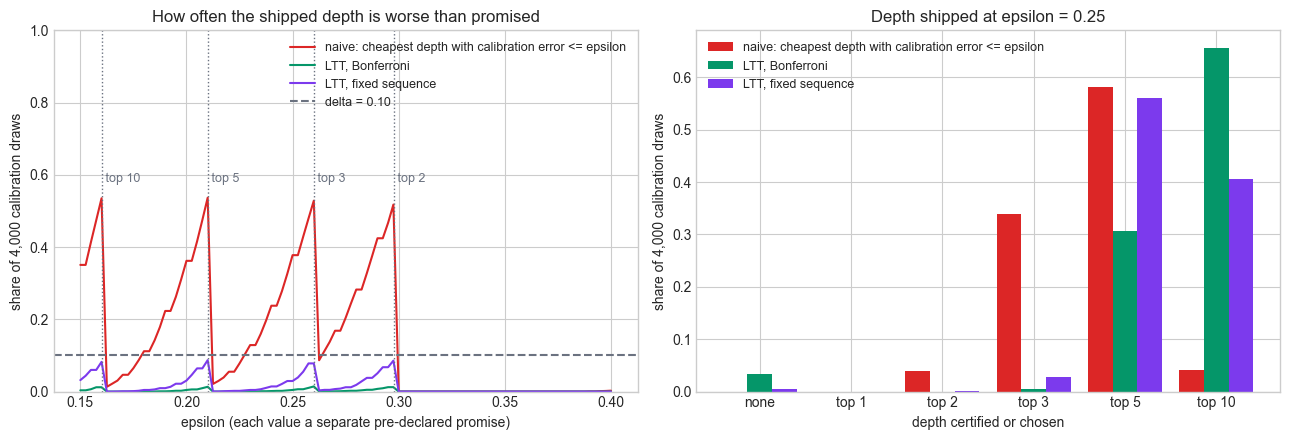

In [15]:
def choose_depths(x, n, eps, delta):
    """Index of the depth chosen by each rule for every row of error counts (draws x depths); -1 = none."""
    naive_ok = x / n <= eps
    pv = binomial_pvalue(x, n, eps)
    bonf_ok = pv <= delta / x.shape[1]
    # Fixed sequence, deepest first: a depth passes if it and every deeper depth pass at delta.
    seq_ok = np.cumprod(pv[:, ::-1] <= delta, axis=1)[:, ::-1].astype(bool)
    cheapest = lambda ok: np.where(ok.any(axis=1), np.argmax(ok, axis=1), -1)
    return {"naive: cheapest depth with calibration error <= epsilon": cheapest(naive_ok),
            "LTT, Bonferroni": cheapest(bonf_ok), "LTT, fixed sequence": cheapest(seq_ok)}


true_risk = wrong.mean(axis=0)                  # the 799 questions as the whole population
rng_boot = np.random.default_rng(RANDOM_SEED + 3)
draws = rng_boot.integers(0, n_q, size=(4000, n_cal))
x_boot = wrong[draws].sum(axis=1)               # error counts: 4,000 calibration sets x 5 depths
print("true error rates:", ", ".join(f"top {k} {r:.4f}" for k, r in zip(DEPTHS, true_risk)))

eps_grid = np.round(np.arange(0.15, 0.40001, 0.0025), 4)
broken = {name: [] for name in choose_depths(x_boot[:1], n_cal, EPSILON, DELTA)}
for eps in eps_grid:
    for name, ch in choose_depths(x_boot, n_cal, eps, DELTA).items():
        broken[name].append(np.mean((ch >= 0) & (true_risk[np.maximum(ch, 0)] > eps)))

at_eps = choose_depths(x_boot, n_cal, EPSILON, DELTA)
for name, ch in at_eps.items():
    shares = {("none" if j < 0 else f"top {DEPTHS[j]}"): np.mean(ch == j) for j in range(-1, len(DEPTHS))}
    print(f"epsilon {EPSILON}: {name}: promise broken in {np.mean((ch >= 0) & (true_risk[np.maximum(ch, 0)] > EPSILON)):.3f} "
          f"of draws; depth shipped {', '.join(f'{k} {v:.2f}' for k, v in shares.items() if v > 0)}")
best = np.argmin(x_boot, axis=1)                # ties go to the cheaper depth
quoted = x_boot[np.arange(len(best)), best] / n_cal
print(f"lowest calibration error: top 10 in {np.mean(best == len(DEPTHS) - 1):.3f} of draws; promise broken in "
      f"{np.mean(true_risk[best] > EPSILON):.3f}; true risk above the quoted calibration error in "
      f"{np.mean(true_risk[best] > quoted):.3f} of draws")
# Without any selection: how often one binomial estimate of top 10's error rate falls below the truth.
r10 = true_risk[-1]
print(f"top 10 alone, no selection: P(calibration error < true rate) = "
      f"{stats.binom.cdf(np.ceil(n_cal * r10) - 1, n_cal, r10):.3f} (exact binomial)")
for name, curve in broken.items():
    print(f"worst epsilon on the grid for {name}: broken in {max(curve):.3f} of draws "
          f"(at epsilon {eps_grid[int(np.argmax(curve))]:.4f})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
styles = {"naive: cheapest depth with calibration error <= epsilon": RED, "LTT, Bonferroni": GREEN,
          "LTT, fixed sequence": PURPLE}
for name, color in styles.items():
    axes[0].plot(eps_grid, broken[name], color=color, label=name)
axes[0].axhline(DELTA, color=GRAY, linestyle="--", label="delta = 0.10")
for k, r in zip(DEPTHS[1:], true_risk[1:]):
    if r < 0.4:
        axes[0].axvline(r, color=GRAY, linestyle=":", linewidth=1)
        axes[0].text(r, 0.58, f" top {k}", color=GRAY, fontsize=9)
axes[0].set_ylim(0, 1.0)
axes[0].set_title("How often the shipped depth is worse than promised")
axes[0].set_xlabel("epsilon (each value a separate pre-declared promise)")
axes[0].set_ylabel("share of 4,000 calibration draws")
axes[0].legend(loc="upper right", fontsize=9)

width = 0.27
cats = ["none"] + [f"top {k}" for k in DEPTHS]
for i, (name, color) in enumerate(styles.items()):
    ch = at_eps[name]
    axes[1].bar(np.arange(len(cats)) + (i - 1) * width, [np.mean(ch == j) for j in range(-1, len(DEPTHS))],
                width=width, color=color, label=name)
axes[1].set_xticks(np.arange(len(cats)))
axes[1].set_xticklabels(cats)
axes[1].set_title(f"Depth shipped at epsilon = {EPSILON}")
axes[1].set_xlabel("depth certified or chosen")
axes[1].set_ylabel("share of 4,000 calibration draws")
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

The true error rates of the population are 47.9%, 29.8%, 26.0%, 21.0% and 16.0% for depths 1, 2, 3,
5 and 10: close to monotone, as the pilot suggested. Even so, the naive rule broke our epsilon =
0.25 promise in 38% of the calibration draws. The reason is in the gray dotted lines of the left
panel: depth 3's true error rate, 26.0%, sits just above 25%, so its calibration error lands at or
below 25% in about a third of the draws, and the naive rule happily ships it (34% of draws); depth
2, at 29.8%, slips through in another 4%. The red curve spikes just below every dotted line, to
about one half (0.537 at its worst, at epsilon = 0.21), because whenever epsilon sits just under a
cheaper depth's true risk the naive rule takes that depth about as often as a coin lands heads. You
do not know where the dotted lines are; that is what you were trying to learn. Both Learn then Test
curves stay under delta at every epsilon: Bonferroni at most 0.014, fixed sequence at most 0.087,
each at its worst just below a depth's true error rate. The right panel is the price: at epsilon =
0.25 the naive rule ships top 3 or top 5 most of the time, Bonferroni ships top 10 in about two
draws in three, and fixed sequence, testing each depth at the full delta, ships top 5 more often
(about 56% of draws), which is why it is the better correction when the cost order is also the
expected order of risk. It pays by spending more of its budget: its worst point, 0.087, sits much
closer to delta than Bonferroni's 0.014, and both are within it. Finally, the depth with the lowest
calibration error. Here it is top 10 in 99.9% of draws, so shipping it never broke the 0.25 promise:
it is safe in this library because it is also the most expensive depth, which is not an answer to
the platform lead. And the number you would quote for it is not a guarantee: its true error rate was
above its calibration error rate in 54% of draws, which is simply what one binomial estimate does
(53.5% for top 10 with no selection at all). A point estimate is not a bound, and it comes with no
probability statement; Learn then Test's certificate does.

Three promises about retrieval, side by side:

| Tool | What is promised | What it assumes | What it does NOT say | In this notebook |
|---|---|---|---|---|
| Split conformal on the weaker passage (section 2) | both supporting passages retrieved for at least 90% of questions, on average over calibration draws | questions exchangeable with the calibration questions | which questions miss; anything per type (bridge 0.907, comparison 1.000) | cut-off 0.332, 6.19 passages, 92.3% on test |
| Conformal risk control (section 3) | expected share of evidence missed at most 10% | exchangeable questions; a bounded loss that never rises as more passages are sent, for every question | that each question misses at most 10%; 18.0% of test questions lost at least one passage | cut-off 0.388, 4.66 passages, 9.2% missed |
| Learn then Test (section 4) | with probability at least 0.9 over the calibration draw, the shipped depth's error rate is at most epsilon | calibration questions a random (i.i.d.) sample of the questions you will serve; candidates, epsilon, delta and test order fixed in advance; a valid p-value per depth | that any single answer is right; anything about depths not tested; anything under another grader | top 10 certified at epsilon 0.25; 13.3% wrong on test |
| Naive: cheapest depth whose calibration error is at most epsilon | nothing | - | - | broke the epsilon = 0.25 promise in 38% of draws |

The table also says what all three share. Each is a promise about questions like the calibration
questions (exchangeable with them for split conformal and CRC; for Learn then Test, the calibration
questions must be a random, i.i.d. sample of the questions you will serve), answered by this
procedure: this embedding model, this passage format, this prompt, this model version and this
grader (field guide §25). HotpotQA is a public benchmark the model may have seen in training, which
may be part of why a single passage already gets about half the answers right (47% on the pilot);
Quill's users do not ask HotpotQA questions (field guide §26). Recalibrate on labelled Quill traffic
before quoting any of these numbers to a customer.

## 5. Common mistakes to avoid

1. **Calling the best fixed top-k "the" depth.** Top-k with a rank score overshoots (0.919 average
   coverage at a 0.90 budget) because ranks take nine values; at equal coverage a calibrated
   similarity cut-off sent 6.33 passages instead of 7.07. Compare rules at equal coverage, and
   report passages and tokens next to coverage (field guide §5, §12).
2. **Reading an expected loss as a per-question promise.** Conformal risk control kept the share of
   evidence missed at 9.2% while 18.0% of test questions lost at least one supporting passage. Say
   "on average", and use the all-or-nothing promise when no question may lose evidence (field guide
   §28).
3. **Applying conformal risk control to a loss that is not monotone per question.** The average
   answer error falls with depth, yet 13 of 199 pilot questions went from right to wrong at a deeper
   depth. The theorem needs every question's loss to be monotone; check it with an assertion, as
   `crc_choose` does, or use Learn then Test (field guide §28).
4. **Shipping the cheapest depth whose calibration error is below epsilon.** That rule broke an
   epsilon = 0.25 promise in 38% of simulated calibration draws; Learn then Test broke it in 0.4%
   (Bonferroni) and 2.9% (fixed sequence). Test every candidate and correct for the number of
   candidates (field guide §28).
5. **Choosing epsilon, the candidates or the test order after seeing the calibration set.** Depth 5
   missed certification with p = 0.1013. Loosening epsilon now to rescue it would be tuning on the
   calibration set (notebook 02, field guide §2). Choose them on a pilot, and plan the calibration
   size from the pilot's power table.
6. **Forgetting the grader and the procedure.** Exact match and F1 at least 0.5 disagree by about 25
   points on the pilot's depth-10 error rate; a change of embedding model, prompt or model version
   invalidates every cut-off in this notebook. Log them with the calibration run and recalibrate
   after any change (field guide §25, §27).
7. **Calibrating on a benchmark and quoting the result for users.** Ten candidates per question with
   two guaranteed supporting passages is not a production library, and a public benchmark may be in
   the model's training data (field guide §26).

## 6. What to say in the product review

**Strong version**

> We calibrated retrieval depth on 300 HotpotQA questions answered by `gpt-4.1-mini` with
> `text-embedding-3-large` retrieval, and checked it on 300 others. Sending every passage scoring at
> least 0.332 in similarity retrieved both supporting passages for 92.3% of test questions (promise:
> at least 90%), at 6.2 passages and about 800 context tokens per question, against 10 passages
> and about 1,400 tokens today (character-based estimates that run about 10% high; the ratios hold). If we accept missing up to 10% of the evidence on average,
> not per question, conformal risk control sends 4.7 passages (about 590 tokens) and missed 9.2% of
> the evidence; that budget lets roughly one question in five lose a supporting passage. For the
> answers, Learn then Test certifies, with probability at least 0.9, that answers with all ten
> passages are wrong at most 25% of the time under our grader (F1 at least 0.5 against the
> reference); they were 13.3% wrong on test. Five passages narrowly failed the test (p = 0.101), so
> we do not claim it. All of this is for HotpotQA-like questions and this exact procedure; before
> launch we recalibrate on 1,000 labelled Quill questions; on questions like these, the pilot
> suggests that would give five passages about a four-in-five chance of certification with
> fixed-sequence testing.

**Weak version**

> Conformal methods guarantee our RAG pipeline retrieves the right evidence 90% of the time and
> answers correctly at least 75% of the time with five passages, so we can halve retrieval.

The weak version claims a certificate the data refused (five passages failed the test), blends two
different promises into one sentence, reads a benchmark result as a promise about Quill's users, and
drops the grader, the procedure and the probability 0.9 that the answer-quality certificate comes
with. The strong version names each promise with its tool, quotes the cost in passages and tokens,
says what "on average" permits, and reports the failed depth instead of hiding it.

### The one-line summary

Three promises, three tools, one question: how little can we send? Split conformal on the weaker
supporting passage's similarity turned "retrieve the evidence" into a promise kept for at least 90%
of questions, at about 6 passages instead of 10. Conformal risk control, which contains split
conformal as the all-or-nothing case, bought a cheaper promise about the average share of evidence
missed, and the average let one question in five lose a passage. For answers, where the loss is not
monotone question by question, Learn then Test tested every depth, corrected for testing five, and
certified only what 300 questions could support, while the naive rule of shipping the cheapest depth
whose calibration error was below epsilon broke the same promise more than a third of the time.

Retrieval is a budget, and a guarantee is the receipt that tells you how little you can spend.